In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

In [3]:
df = pd.read_csv('titanic.csv')
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
413,1305,0,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S
414,1306,1,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
415,1307,0,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
416,1308,0,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S


In [4]:
df=df.drop(['PassengerId','Name','Ticket','Cabin'],axis=1)
df

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,34.5,0,0,7.8292,Q
1,1,3,female,47.0,1,0,7.0000,S
2,0,2,male,62.0,0,0,9.6875,Q
3,0,3,male,27.0,0,0,8.6625,S
4,1,3,female,22.0,1,1,12.2875,S
...,...,...,...,...,...,...,...,...
413,0,3,male,NaN,0,0,8.0500,S
414,1,1,female,39.0,0,0,108.9000,C
415,0,3,male,38.5,0,0,7.2500,S
416,0,3,male,NaN,0,0,8.0500,S


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  418 non-null    int64  
 1   Pclass    418 non-null    int64  
 2   Sex       418 non-null    object 
 3   Age       332 non-null    float64
 4   SibSp     418 non-null    int64  
 5   Parch     418 non-null    int64  
 6   Fare      417 non-null    float64
 7   Embarked  418 non-null    object 
dtypes: float64(2), int64(4), object(2)
memory usage: 26.3+ KB


In [6]:
df.describe()

,Survived,Pclass,Age,SibSp,Parch,Fare
count,418.000000,418.000000,332.000000,418.000000,418.000000,417.000000
mean,0.363636,2.265550,30.272590,0.447368,0.392344,35.627188
std,0.481622,0.841838,14.181209,0.896760,0.981429,55.907576
min,0.000000,1.000000,0.170000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,21.000000,0.000000,0.000000,7.895800
50%,0.000000,3.000000,27.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,39.000000,1.000000,0.000000,31.500000
max,1.000000,3.000000,76.000000,8.000000,9.000000,512.329200


In [7]:
df['Age'].mean()

30.272590361445783

In [8]:
df['Age'].fillna(df['Age'].mean(),inplace=True)

In [9]:
df.isna().sum()

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        1
Embarked    0
dtype: int64

In [10]:
df.dropna(inplace=True)
df

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,34.50000,0,0,7.8292,Q
1,1,3,female,47.00000,1,0,7.0000,S
2,0,2,male,62.00000,0,0,9.6875,Q
3,0,3,male,27.00000,0,0,8.6625,S
4,1,3,female,22.00000,1,1,12.2875,S
...,...,...,...,...,...,...,...,...
413,0,3,male,30.27259,0,0,8.0500,S
414,1,1,female,39.00000,0,0,108.9000,C
415,0,3,male,38.50000,0,0,7.2500,S
416,0,3,male,30.27259,0,0,8.0500,S


In [11]:
from sklearn.preprocessing import LabelEncoder,OneHotEncoder
le = LabelEncoder()

In [12]:
df

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,34.50000,0,0,7.8292,Q
1,1,3,female,47.00000,1,0,7.0000,S
2,0,2,male,62.00000,0,0,9.6875,Q
3,0,3,male,27.00000,0,0,8.6625,S
4,1,3,female,22.00000,1,1,12.2875,S
...,...,...,...,...,...,...,...,...
413,0,3,male,30.27259,0,0,8.0500,S
414,1,1,female,39.00000,0,0,108.9000,C
415,0,3,male,38.50000,0,0,7.2500,S
416,0,3,male,30.27259,0,0,8.0500,S


In [13]:
df['Sex'] = le.fit_transform(df['Sex'])
df

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,1,34.50000,0,0,7.8292,Q
1,1,3,0,47.00000,1,0,7.0000,S
2,0,2,1,62.00000,0,0,9.6875,Q
3,0,3,1,27.00000,0,0,8.6625,S
4,1,3,0,22.00000,1,1,12.2875,S
...,...,...,...,...,...,...,...,...
413,0,3,1,30.27259,0,0,8.0500,S
414,1,1,0,39.00000,0,0,108.9000,C
415,0,3,1,38.50000,0,0,7.2500,S
416,0,3,1,30.27259,0,0,8.0500,S


In [14]:
df['Embarked'] = le.fit_transform(df['Embarked'])
df

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,1,34.50000,0,0,7.8292,1
1,1,3,0,47.00000,1,0,7.0000,2
2,0,2,1,62.00000,0,0,9.6875,1
3,0,3,1,27.00000,0,0,8.6625,2
4,1,3,0,22.00000,1,1,12.2875,2
...,...,...,...,...,...,...,...,...
413,0,3,1,30.27259,0,0,8.0500,2
414,1,1,0,39.00000,0,0,108.9000,0
415,0,3,1,38.50000,0,0,7.2500,2
416,0,3,1,30.27259,0,0,8.0500,2


In [15]:
y=df['Survived']
x=df.drop(['Survived'],axis=1)

In [16]:
x

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,1,34.50000,0,0,7.8292,1
1,3,0,47.00000,1,0,7.0000,2
2,2,1,62.00000,0,0,9.6875,1
3,3,1,27.00000,0,0,8.6625,2
4,3,0,22.00000,1,1,12.2875,2
...,...,...,...,...,...,...,...
413,3,1,30.27259,0,0,8.0500,2
414,1,0,39.00000,0,0,108.9000,0
415,3,1,38.50000,0,0,7.2500,2
416,3,1,30.27259,0,0,8.0500,2


In [17]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier,plot_tree

In [18]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.3,random_state=31)
dtg = DecisionTreeClassifier()
dte = DecisionTreeClassifier(criterion='entropy')
dtl = DecisionTreeClassifier(criterion='log_loss')

In [19]:
dtg.fit(x_train,y_train)
dte.fit(x_train,y_train)
dtl.fit(x_train,y_train)

DecisionTreeClassifier(criterion='log_loss')

In [20]:
from matplotlib.pylab import rcParams
rcParams['figure.figsize']= 200,100
plot_tree(dtg)

[Text(0.5, 0.75, 'x[1] <= 0.5\ngini = 0.473\nsamples = 291\nvalue = [179, 112]'),
 Text(0.25, 0.25, 'gini = 0.0\nsamples = 112\nvalue = [0, 112]'),
 Text(0.75, 0.25, 'gini = 0.0\nsamples = 179\nvalue = [179, 0]')]

In [21]:
plot_tree(dte)

[Text(0.5, 0.75, 'x[1] <= 0.5\nentropy = 0.961\nsamples = 291\nvalue = [179, 112]'),
 Text(0.25, 0.25, 'entropy = 0.0\nsamples = 112\nvalue = [0, 112]'),
 Text(0.75, 0.25, 'entropy = 0.0\nsamples = 179\nvalue = [179, 0]')]

[Text(0.5, 0.75, 'x[1] <= 0.5\nlog_loss = 0.961\nsamples = 291\nvalue = [179, 112]'),
 Text(0.25, 0.25, 'log_loss = 0.0\nsamples = 112\nvalue = [0, 112]'),
 Text(0.75, 0.25, 'log_loss = 0.0\nsamples = 179\nvalue = [179, 0]')]

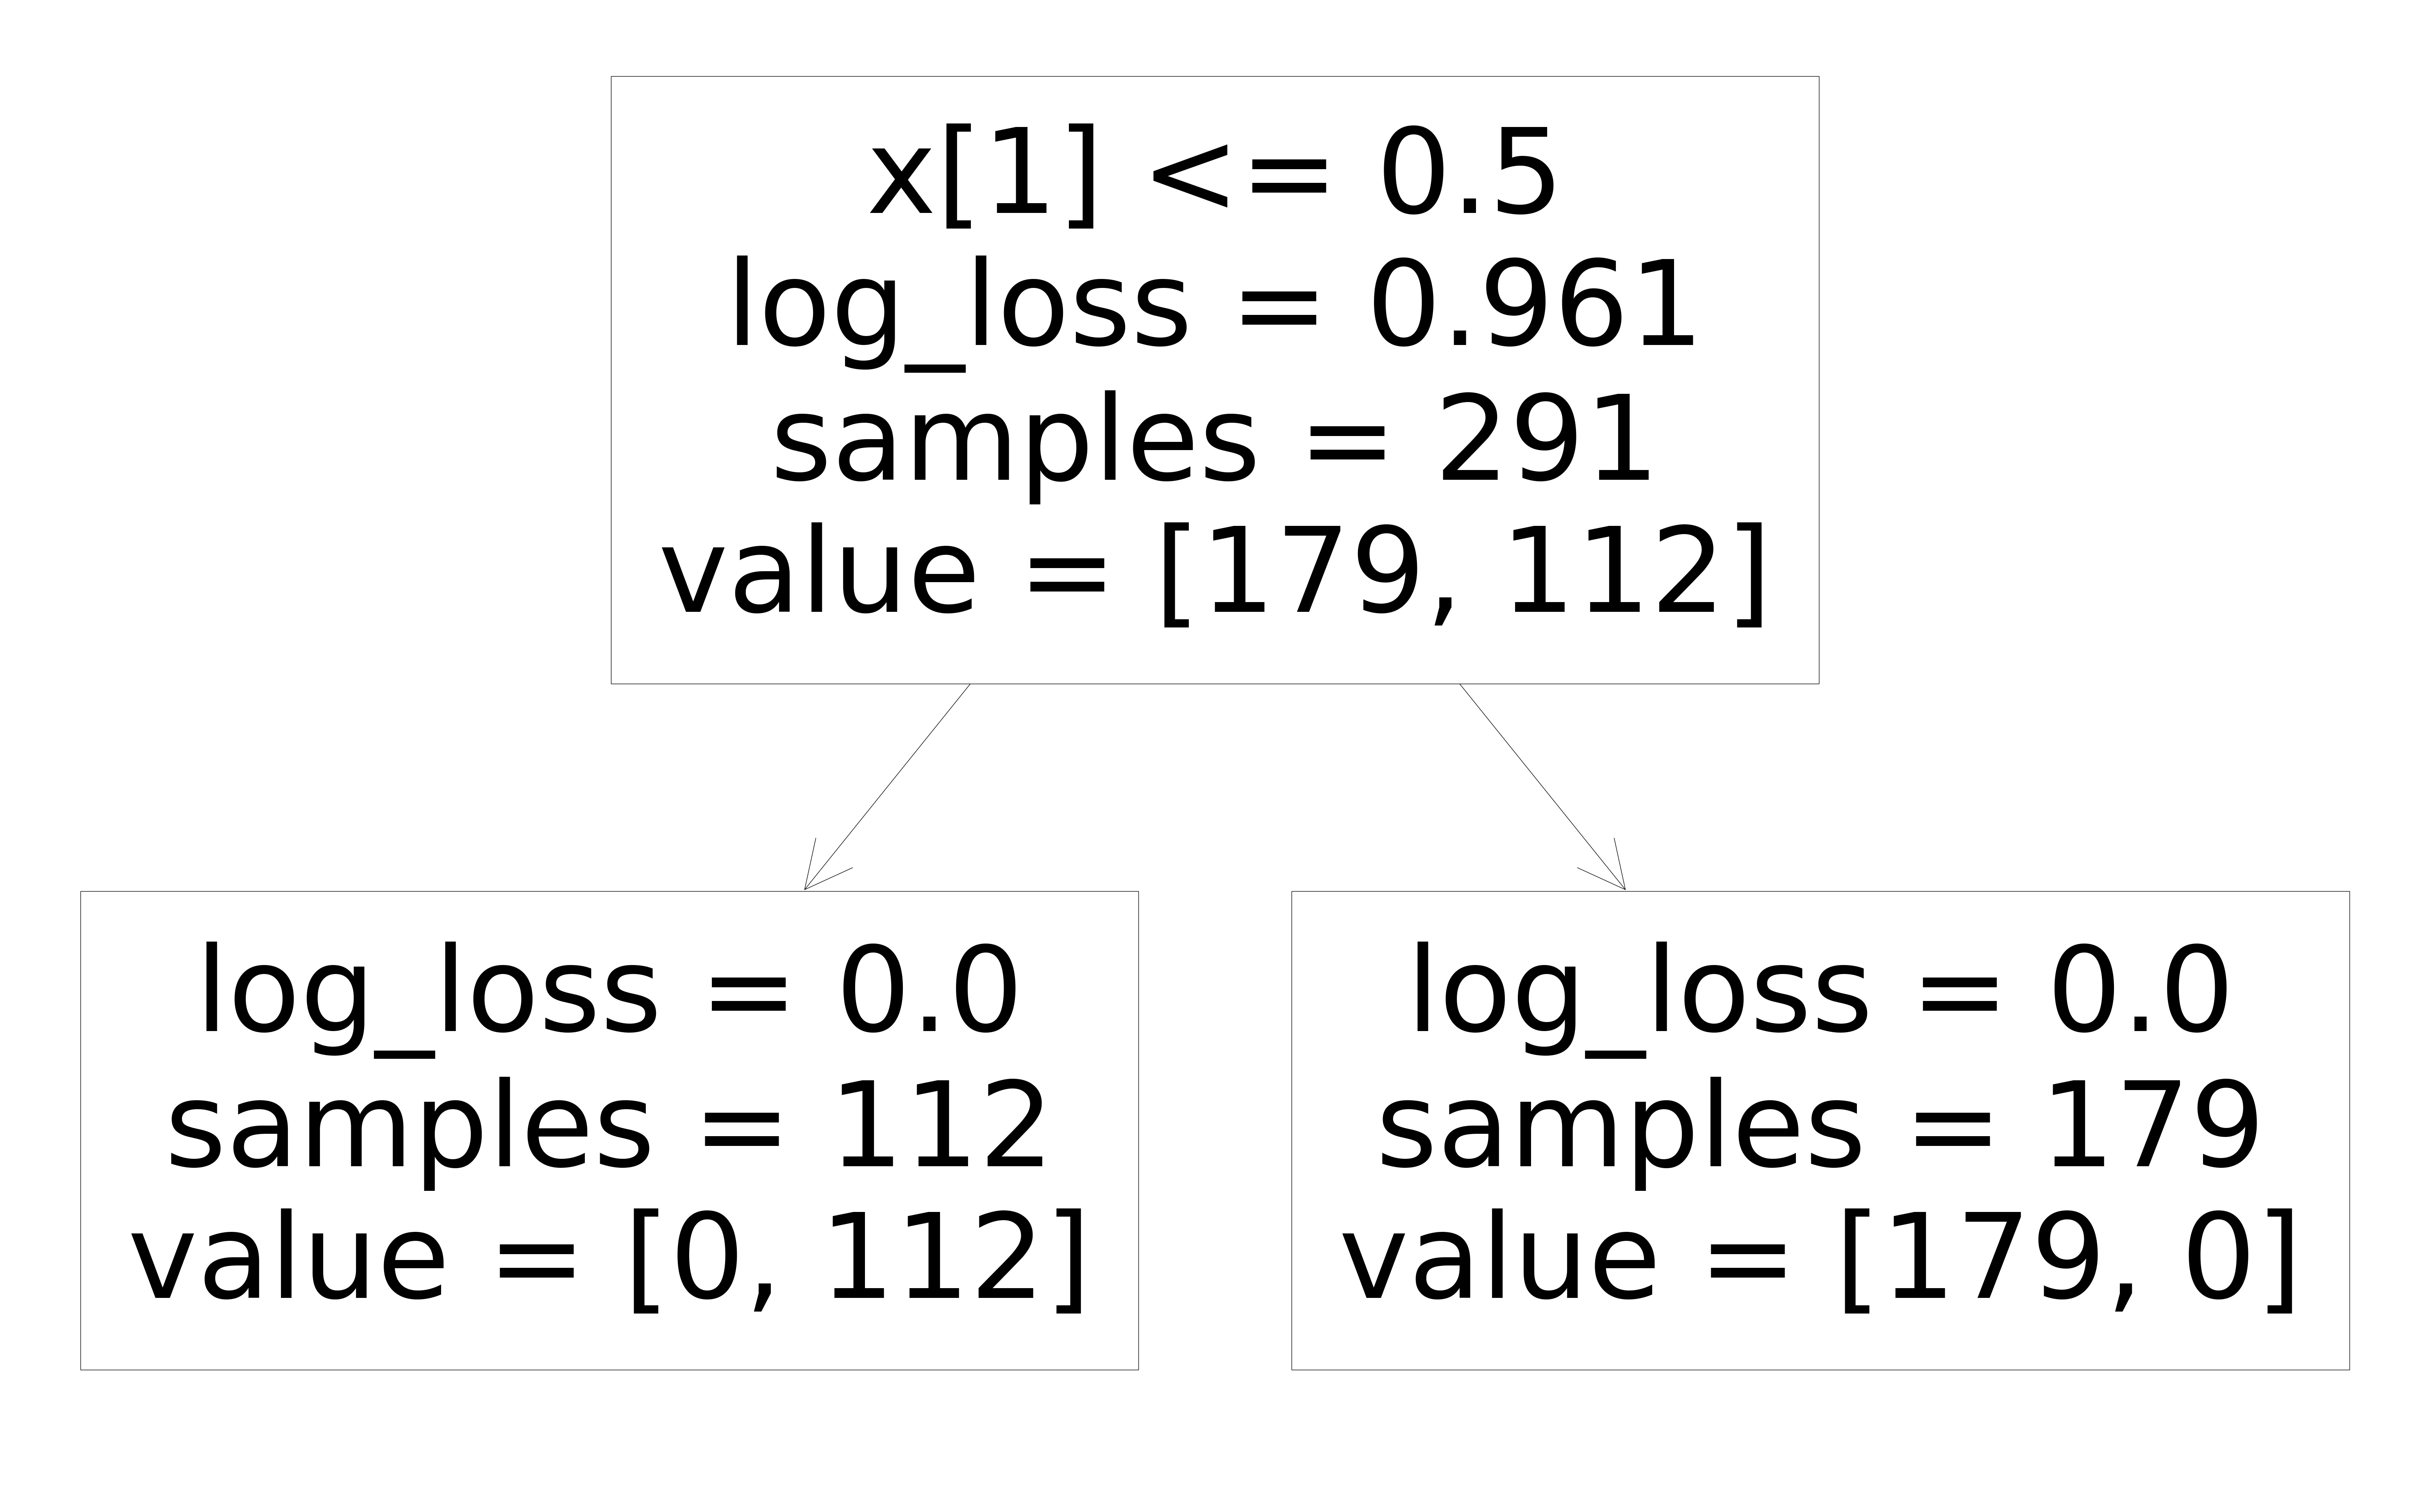

In [22]:
from matplotlib.pylab import rcParams
rcParams['figure.figsize']= 80,50
plot_tree(dtl)

In [23]:
df['Survived'].unique()

array([0, 1])

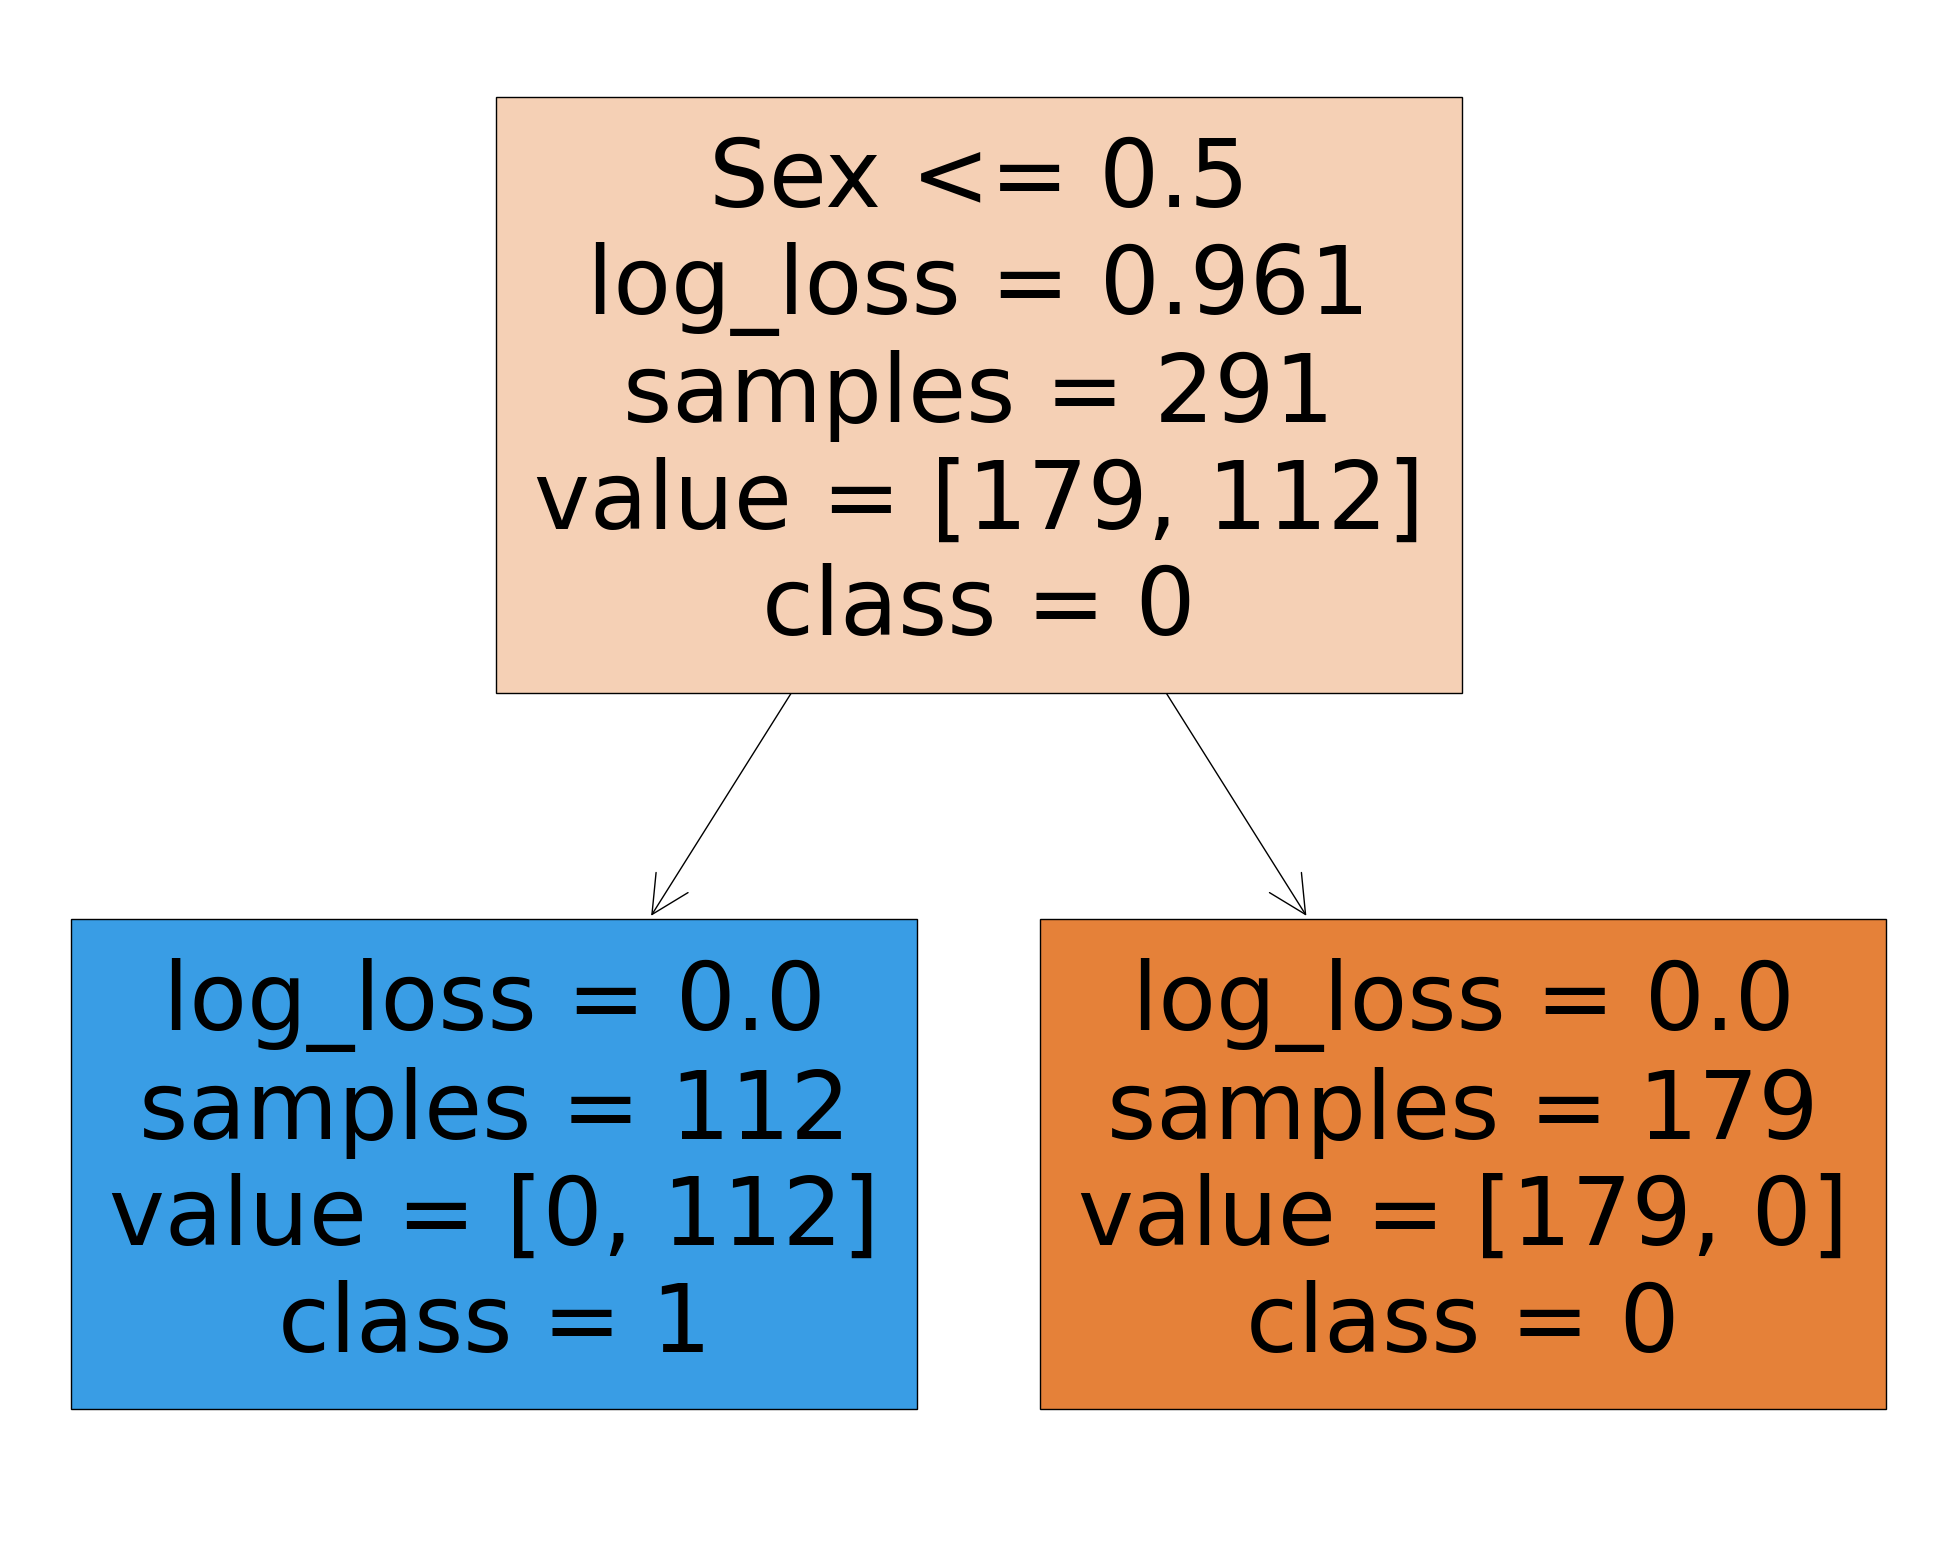

In [24]:
from sklearn.datasets import load_iris
iris=load_iris()
fig = plt.figure(figsize=(25,20))
_ = plot_tree(dtl, 
                   feature_names=['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
       'Embarked'],
                   class_names=['0','1'],
                   filled=True)

In [25]:
dtg.score(x_test,y_test)

1.0

In [26]:
dtg.predict_proba(x_test)

array([[1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [1., 0.

In [27]:
pd.get_dummies(df,columns=['Embarked'],dtype=int,drop_first=True)

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_1,Embarked_2
0,0,3,1,34.50000,0,0,7.8292,1,0
1,1,3,0,47.00000,1,0,7.0000,0,1
2,0,2,1,62.00000,0,0,9.6875,1,0
3,0,3,1,27.00000,0,0,8.6625,0,1
4,1,3,0,22.00000,1,1,12.2875,0,1
...,...,...,...,...,...,...,...,...,...
413,0,3,1,30.27259,0,0,8.0500,0,1
414,1,1,0,39.00000,0,0,108.9000,0,0
415,0,3,1,38.50000,0,0,7.2500,0,1
416,0,3,1,30.27259,0,0,8.0500,0,1


In [30]:

df.dropna(inplace=True)
df.isna().sum()

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

In [31]:
df

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,1,34.50000,0,0,7.8292,1
1,1,3,0,47.00000,1,0,7.0000,2
2,0,2,1,62.00000,0,0,9.6875,1
3,0,3,1,27.00000,0,0,8.6625,2
4,1,3,0,22.00000,1,1,12.2875,2
...,...,...,...,...,...,...,...,...
413,0,3,1,30.27259,0,0,8.0500,2
414,1,1,0,39.00000,0,0,108.9000,0
415,0,3,1,38.50000,0,0,7.2500,2
416,0,3,1,30.27259,0,0,8.0500,2


In [32]:
y=df['Survived']
x=df.drop(['PassengerId','Name','Ticket','Cabin'],axis=1)

KeyError: "['PassengerId', 'Name', 'Ticket', 'Cabin'] not found in axis"

In [103]:
from sklearn.model_selection import train_test_split

In [104]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.3,random_state=42)
x_train

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
118,0,1,1,36.00000,0,0,75.2417,C
271,0,3,1,30.27259,0,0,7.7500,Q
114,1,1,0,63.00000,1,0,221.7792,S
311,0,3,1,22.00000,0,0,7.2250,C
131,0,1,1,53.00000,0,0,28.5000,C
...,...,...,...,...,...,...,...,...
71,0,3,1,21.00000,0,0,7.8958,S
106,0,3,1,21.00000,0,0,7.8208,Q
270,0,1,1,46.00000,0,0,75.2417,C
348,0,2,1,24.00000,0,0,13.5000,S


In [16]:
from sklearn.impute import SimpleImputer
imp = SimpleImputer(missing_values=np.nan,strategy='mean')

imp.fit(df[['Age']])
age=imp.transform(df[['Age']])


In [18]:
df['Age']=age

In [19]:
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.50000,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.00000,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.00000,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.00000,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.00000,1,1,3101298,12.2875,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
413,1305,0,3,"Spector, Mr. Woolf",male,30.27259,0,0,A.5. 3236,8.0500,NaN,S
414,1306,1,1,"Oliva y Ocana, Dona. Fermina",female,39.00000,0,0,PC 17758,108.9000,C105,C
415,1307,0,3,"Saether, Mr. Simon Sivertsen",male,38.50000,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
416,1308,0,3,"Ware, Mr. Frederick",male,30.27259,0,0,359309,8.0500,NaN,S


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Survived     418 non-null    int64  
 2   Pclass       418 non-null    int64  
 3   Name         418 non-null    object 
 4   Sex          418 non-null    object 
 5   Age          418 non-null    float64
 6   SibSp        418 non-null    int64  
 7   Parch        418 non-null    int64  
 8   Ticket       418 non-null    object 
 9   Fare         417 non-null    float64
 10  Cabin        91 non-null     object 
 11  Embarked     418 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 39.3+ KB


In [24]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64

In [8]:
np.nan

nan

In [ ]:
from sklearn.tree import DecisionTreeClassifier


In [33]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier,plot_tree

iris=load_iris()
iris
x = iris['data']
y = iris['target']
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [45]:
clf = DecisionTreeClassifier(min_samples_leaf=10) 
clf.fit(x,y)

DecisionTreeClassifier(min_samples_leaf=10)

[Text(0.4444444444444444, 0.9, 'x[3] <= 0.8\ngini = 0.667\nsamples = 150\nvalue = [50, 50, 50]'),
 Text(0.3333333333333333, 0.7, 'gini = 0.0\nsamples = 50\nvalue = [50, 0, 0]'),
 Text(0.5555555555555556, 0.7, 'x[3] <= 1.75\ngini = 0.5\nsamples = 100\nvalue = [0, 50, 50]'),
 Text(0.3333333333333333, 0.5, 'x[2] <= 4.65\ngini = 0.168\nsamples = 54\nvalue = [0, 49, 5]'),
 Text(0.2222222222222222, 0.3, 'x[2] <= 4.45\ngini = 0.049\nsamples = 40\nvalue = [0, 39, 1]'),
 Text(0.1111111111111111, 0.1, 'gini = 0.0\nsamples = 29\nvalue = [0, 29, 0]'),
 Text(0.3333333333333333, 0.1, 'gini = 0.165\nsamples = 11\nvalue = [0, 10, 1]'),
 Text(0.4444444444444444, 0.3, 'gini = 0.408\nsamples = 14\nvalue = [0, 10, 4]'),
 Text(0.7777777777777778, 0.5, 'x[0] <= 6.25\ngini = 0.043\nsamples = 46\nvalue = [0, 1, 45]'),
 Text(0.6666666666666666, 0.3, 'gini = 0.165\nsamples = 11\nvalue = [0, 1, 10]'),
 Text(0.8888888888888888, 0.3, 'gini = 0.0\nsamples = 35\nvalue = [0, 0, 35]')]

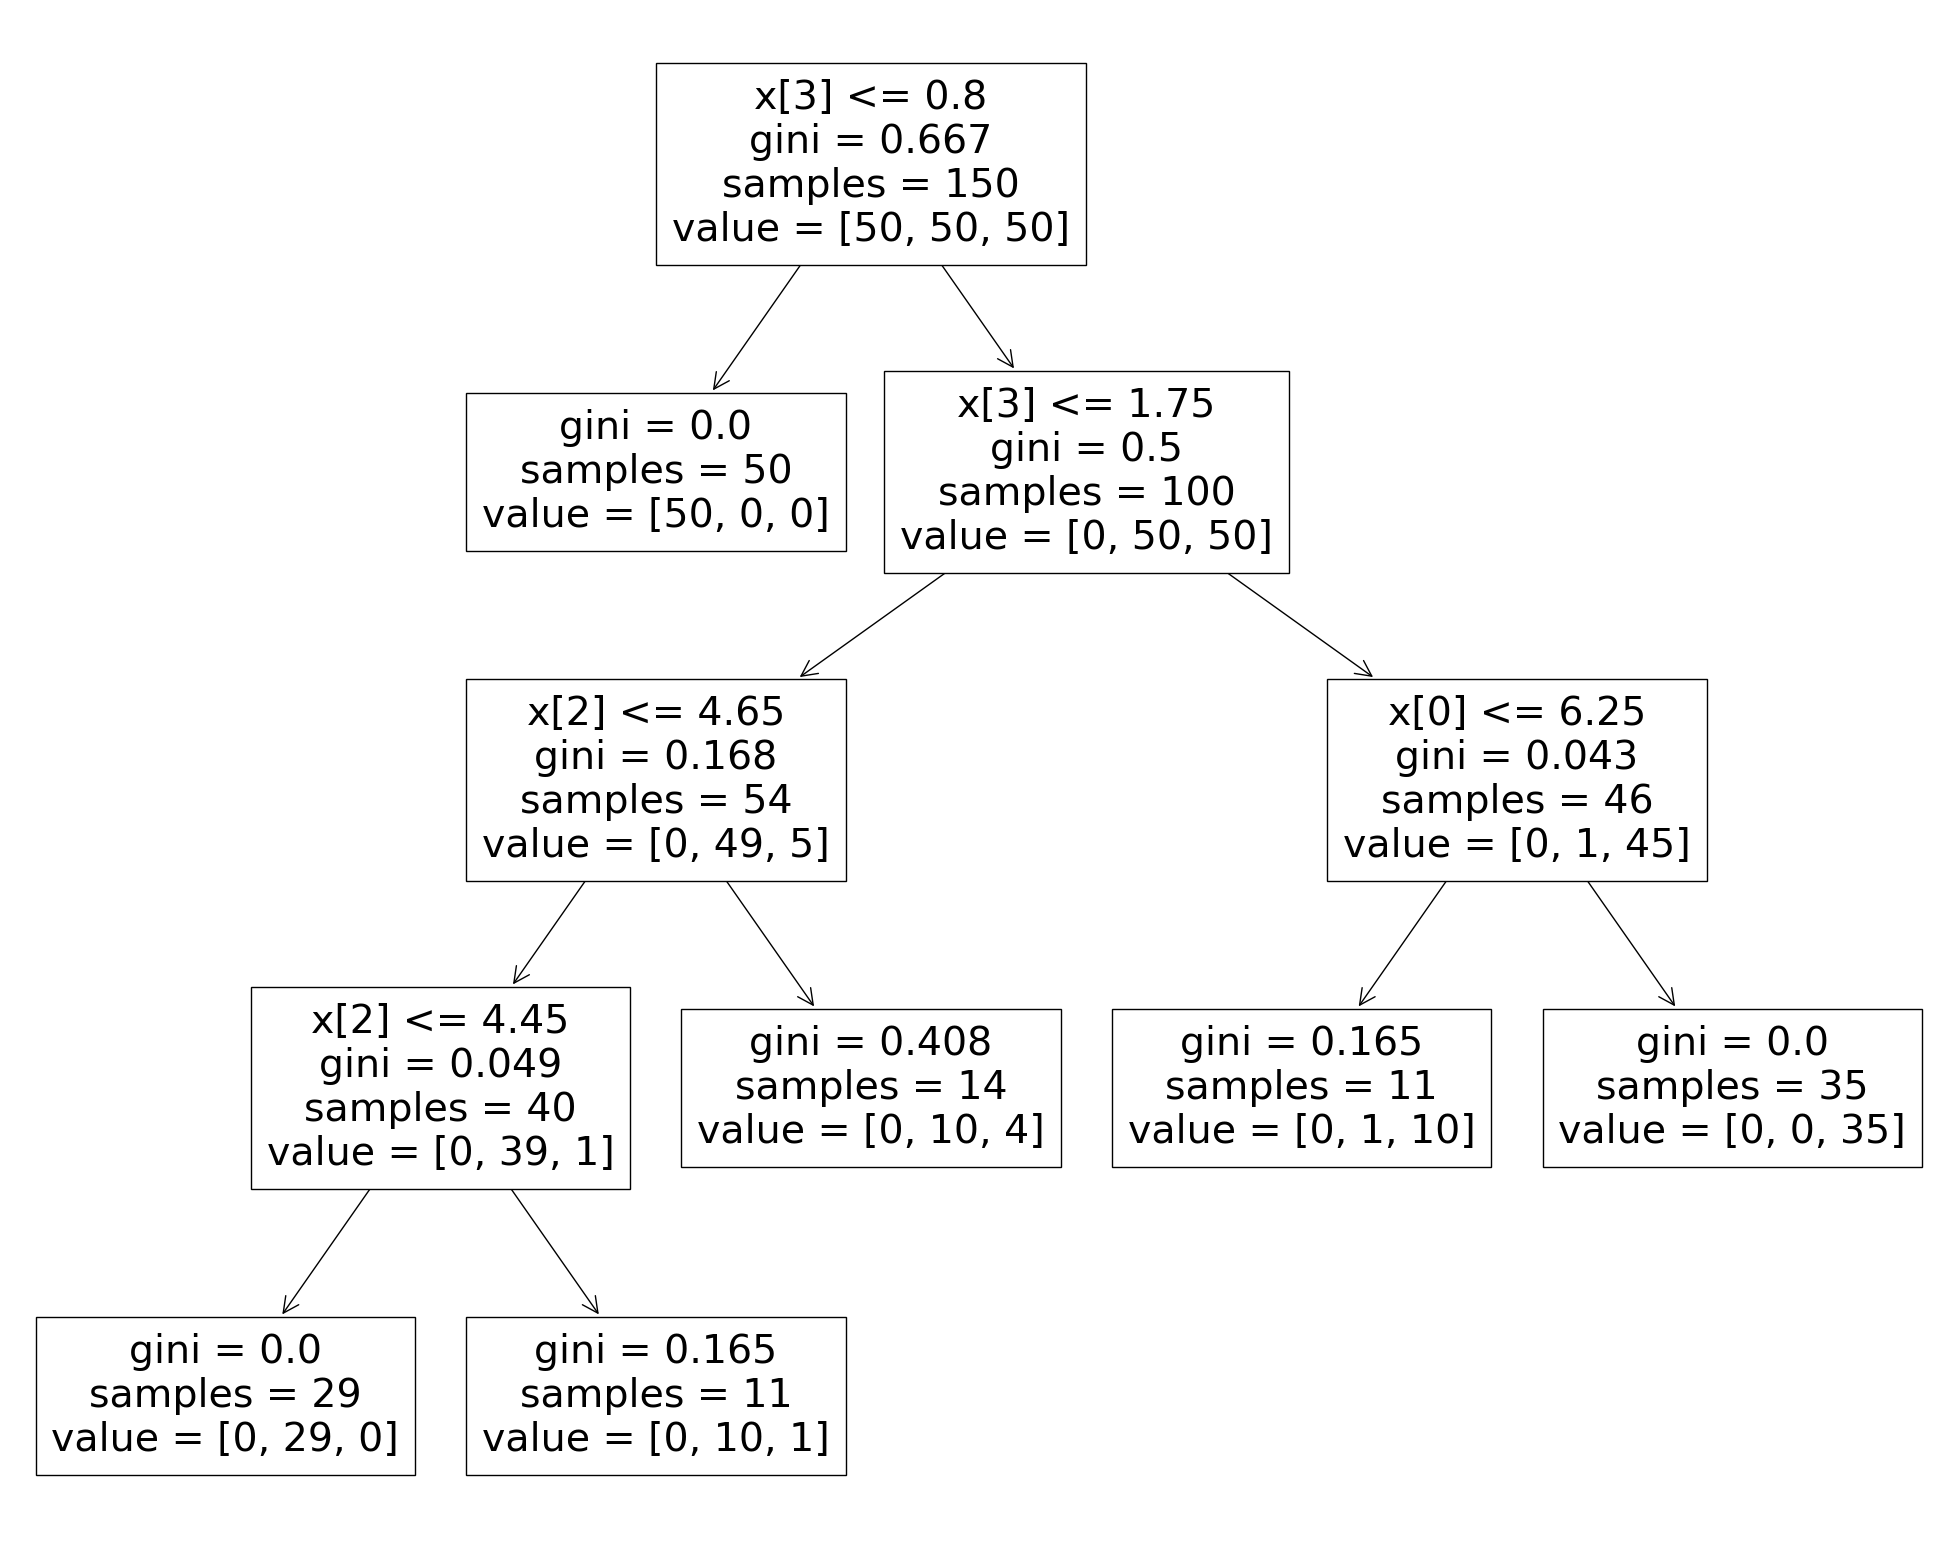

In [46]:
fig = plt.figure(figsize=(25,20))
plot_tree(clf)